# Notebook 06 — Validación cruzada anidada, optimización y comparación con TabPFN

## 1. Importaciones y configuración

Parámetros globales. Misma semilla (42) y mismo esquema 10×5 que el Notebook 04, así que las 50 particiones coinciden con las del baseline. 

In [1]:
import os
import time
import warnings
import numpy as np
import joblib
import pandas as pd
from scipy import stats
from scipy.stats import wilcoxon, friedmanchisquare
from tabpfn import TabPFNClassifier
import shap
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    RepeatedStratifiedKFold, StratifiedKFold, RandomizedSearchCV
)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
import xgboost as xgb

In [2]:
warnings.filterwarnings("ignore")

### Configuración

Parámetros del experimento.

| Parámetro | Valor | Para qué sirve |
|---|---|---|
| `CARPETA_RESULTADOS` | `results` | Carpeta de entrada y salida. Es la misma donde los notebooks 03, 04 y 05 dejaron sus archivos: este notebook lee de ahí y guarda también ahí sus resultados. |
| `CARPETA_FIGURAS` | `fig` | Carpeta donde se guardan las figuras. |
| `SEMILLA` | 42 | Es la misma semilla que usa el notebook 04, de modo que los 50 folds son exactamente las mismas particiones de pacientes que en el baseline y la comparación es justa. |
| `N_FEATURES_OBJETIVO` | 12 | Variables que se conservan en cada fold (las 12 más importantes según XGBoost). |
| `N_SPLITS_EXTERNO` × `N_REPEATS_EXTERNO` | 10 × 5 | Validación cruzada externa: 10 particiones repetidas 5 veces, es decir, 50 evaluaciones. Es la que mide el rendimiento. |
| `N_SPLITS_INTERNO` | 5 | Validación cruzada interna: dentro de cada fold externo se usa solo su conjunto de entrenamiento para buscar hiperparámetros. |
| `N_ITER_RANDOM_SEARCH` | 20 | Combinaciones aleatorias de hiperparámetros que se prueban en cada búsqueda. |
| `ALPHA` | 0,05 | Nivel de significación de los tests estadísticos. |
| `CLASICOS` | XGBoost, Regresión Logística, Random Forest | Los tres algoritmos clásicos que se comparan con TabPFN. |
| `SLUG` | nombres cortos | Nombres para los archivos de salida. |

In [3]:
CARPETA_RESULTADOS = "results"
CARPETA_FIGURAS = "fig"

SEMILLA = 42                       
N_FEATURES_OBJETIVO = 12

# CV externa: 10 particiones x 5 repeticiones = 50 evaluaciones. Es la que mide el rendimiento.
N_SPLITS_EXTERNO = 10
N_REPEATS_EXTERNO = 5

 # CV interna de la búsqueda de hiperparámetros
N_SPLITS_INTERNO = 5              
N_ITER_RANDOM_SEARCH = 20

ALPHA = 0.05

CLASICOS = ['XGBoost', 'Regresión Logística', 'Random Forest']

SLUG = {
    'XGBoost': 'xgboost',
    'Regresión Logística': 'regresion_logistica',
    'Random Forest': 'random_forest',
}

os.makedirs(CARPETA_RESULTADOS, exist_ok=True)
os.makedirs(CARPETA_FIGURAS, exist_ok=True)

## 2. Carga de datos: 85 pacientes

- `X`: variables predictoras de los 85 pacientes (17 columnas tras la codificación).
- `y`: ypN binario (1 = afectación ganglionar tras la neoadyuvancia).

Se usan **todos** los pacientes: no hay conjunto de test reservado y la evaluación se hace solo mediante validación cruzada. Los archivos `X_full.csv` e `y_full.csv` los generó un notebook anterior y están en la carpeta de resultados.

In [4]:
X = pd.read_csv(f"{CARPETA_RESULTADOS}/X_full.csv")
y = pd.read_csv(f"{CARPETA_RESULTADOS}/y_full.csv").squeeze()
columnas = X.columns.tolist()
N_TOTAL = len(X)
print(f"Dataset completo: X={X.shape}, y={y.shape}")

Dataset completo: X=(85, 17), y=(85,)


El conjunto de datos final contiene 85 pacientes con cáncer de mama localmente avanzado tratadas con neoadyuvancia. De las variables clínicas, biológicas y derivadas de PET/CT, quedan 17 columnas predictoras tras excluir las redundantes (PR, anti-HER2 y sus ciclos, ΔTLG) y codificar las categóricas. De las 85 pacientes, 55 (64,7 %) fueron ypN0 y 30 (35,3 %) ypN+, considerando ypN1mi como positivo. Dado el tamaño muestral, no se reservó ningún subconjunto de test independiente y todo el rendimiento se estimó mediante validación cruzada estratificada repetida (10 particiones × 5 repeticiones = 50 evaluaciones).

## 3. CV anidada 10x5: selección de características y optimización

### 3.1 Modelos por defecto

`crear_estimador` crea cada modelo con los hiperparámetros por defecto del notebook 04, para que la comparación con el baseline sea coherente. El peso de la clase positiva se calcula con el train del fold, sin mirar el test. En la regresión logística el escalado va dentro del `Pipeline`, de modo que en la búsqueda interna se reajusta en cada fold interno sin fuga hacia el fold de validación.

In [5]:
def crear_estimador(nombre, y_tr):
    peso = (y_tr == 0).sum() / max((y_tr == 1).sum(), 1)
    if nombre == 'XGBoost':
        return xgb.XGBClassifier(
            n_estimators=100, max_depth=3, learning_rate=0.1,
            scale_pos_weight=peso, random_state=SEMILLA,
            eval_metric='logloss', n_jobs=1
        )
    if nombre == 'Regresión Logística':
        return Pipeline([
            ('scaler', StandardScaler()),
            ('classifier', LogisticRegression(
                penalty='elasticnet', l1_ratio=0.5, solver='saga',
                class_weight='balanced', max_iter=5000, random_state=SEMILLA
            )),
        ])
    if nombre == 'Random Forest':
        return RandomForestClassifier(
            n_estimators=200, max_depth=4, class_weight='balanced',
            random_state=SEMILLA, n_jobs=1
        )
    raise ValueError(f"Modelo desconocido: {nombre}")

### 3.2 Espacios de búsqueda

Hiperparámetros que prueba la búsqueda aleatoria de cada algoritmo: `N_ITER_RANDOM_SEARCH` combinaciones de estas listas. En la regresión logística, el prefijo `classifier__` indica que el parámetro pertenece al clasificador dentro del pipeline.

In [6]:
PARAM_DIST = {
    'XGBoost': {
        'n_estimators': [50, 100, 200, 300],
        'max_depth': [2, 3, 4, 5, 6],
        'learning_rate': [0.01, 0.05, 0.1, 0.2],
        'subsample': [0.6, 0.8, 1.0],
        'colsample_bytree': [0.6, 0.8, 1.0],
        'min_child_weight': [1, 3, 5],
    },
    'Regresión Logística': {
        'classifier__C': [0.01, 0.1, 0.5, 1, 2, 5, 10],
        'classifier__l1_ratio': [0.0, 0.25, 0.5, 0.75, 1.0],
    },
    'Random Forest': {
        'n_estimators': [100, 200, 300, 500],
        'max_depth': [3, 4, 5, 6, None],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4],
        'max_features': ['sqrt', 'log2', 0.5],
    },
}

### 3.3 Nombres de las filas de resultados y registro de resultados

### Nombres de las filas de resultados

*Selección anidada* = variables elegidas dentro del fold. *Optimizado* = además se buscaron sus hiperparámetros dentro del fold. `nombre_final` es la versión que se considera final de cada clásico (la optimizada).

In [7]:
def nombre_defecto(m):
    return f"{m} (selección anidada)"


def nombre_opt(m):
    return f"{m} (optimizado, selección anidada)"


def nombre_final(m):
    return nombre_opt(m)


NOMBRE_TABPFN = 'TabPFN (selección anidada)'

Registro de resultados por fold

`registrar` guarda el resultado de un modelo en un fold: su AUC-ROC (para los tests) y la matriz de confusión (en el orden [verdaderos positivos, falsos negativos, verdaderos negativos, falsos positivos]) evaluada bajo el umbral de decisión estándar por defecto ($0.50$). Los conteos se agrupan por repetición, ya que cada repetición reparte los 85 pacientes entre sus 10 folds.   .

In [8]:
def registrar(nombre, proba, y_te, rep_idx):
    resultados[nombre].append(roc_auc_score(y_te, proba))
    pred = (np.asarray(proba) >=0.5).astype(int)
    real = np.asarray(y_te).astype(int)
    conteos[nombre][rep_idx] += [
        np.sum((pred == 1) & (real == 1)), # Verdaderos Positivos (TP)
        np.sum((pred == 0) & (real == 1)), # Falsos Negativos (FN)
        np.sum((pred == 0) & (real == 0)), # Verdaderos Negativos (TN)
        np.sum((pred == 1) & (real == 0)), # Falsos Positivos (FP)
    ]

### 3.4 Preparación

Validación cruzada externa estratificada (mantiene la proporción de ypN+ en cada fold) y repetida: 10 folds × 5 repeticiones = 50 evaluaciones. Esta celda crea la partición y los contenedores donde el bucle guardará los resultados:

- `resultados`: AUC de cada fold y modelo (50 valores por modelo), que luego se usan pareados en los tests estadísticos.
- `conteos`: por modelo y repetición, [verdaderos positivos, falsos negativos, verdaderos negativos, falsos positivos].
- `importancias_acumuladas` y `conteo_seleccion`: importancia sumada y número de folds en que cada variable entra en el top-N.
- `hp_por_modelo`: mejores hiperparámetros de cada fold.

In [9]:
cv_externa = RepeatedStratifiedKFold(
    n_splits=N_SPLITS_EXTERNO, n_repeats=N_REPEATS_EXTERNO, random_state=SEMILLA
)
n_folds_total = N_SPLITS_EXTERNO * N_REPEATS_EXTERNO
print(f"[CV EXTERNA] {N_SPLITS_EXTERNO}-fold x {N_REPEATS_EXTERNO} rep. = {n_folds_total} evaluaciones")

resultados = {nombre_defecto(m): [] for m in CLASICOS}
for m in CLASICOS:
    resultados[nombre_opt(m)] = []
resultados[NOMBRE_TABPFN] = []

conteos = {nombre: np.zeros((N_REPEATS_EXTERNO, 4), dtype=int) for nombre in resultados}

importancias_acumuladas = pd.Series(0.0, index=columnas)
conteo_seleccion = pd.Series(0, index=columnas)
hp_por_modelo = {m: [] for m in CLASICOS}

[CV EXTERNA] 10-fold x 5 rep. = 50 evaluaciones


### 3.5 Imputación y selección de variables (paso A)

Dos funciones que se aplican con el train de cada fold: `imputar_fold` rellena los valores perdidos con la mediana del train, y `seleccionar_variables` entrena un XGBoost solo con el train y devuelve la importancia de cada variable. Cada fold puede elegir variables distintas.

In [10]:
def imputar_fold(X_tr, X_te):
    imputer = SimpleImputer(strategy='median').fit(X_tr)
    return (pd.DataFrame(imputer.transform(X_tr), columns=columnas),
            pd.DataFrame(imputer.transform(X_te), columns=columnas))


def seleccionar_variables(X_tr, y_tr):
    selector = xgb.XGBClassifier(
        n_estimators=100, max_depth=3, learning_rate=0.1,
        random_state=SEMILLA, eval_metric='logloss'
    )
    selector.fit(X_tr, y_tr)
    return pd.Series(selector.feature_importances_, index=columnas)

### 3.6 Clásicos con hiperparámetros por defecto (paso B)

Entrena y evalúa cada clásico con sus hiperparámetros por defecto sobre las variables elegidas en el fold. Mide el efecto de la selección de variables por sí sola.

In [11]:
def evaluar_por_defecto(X_tr, y_tr, X_te, y_te, rep_idx):
    for m in CLASICOS:
        est = crear_estimador(m, y_tr)
        est.fit(X_tr, y_tr)
        registrar(nombre_defecto(m), est.predict_proba(X_te)[:, 1], y_te, rep_idx)

### 3.7 Optimización anidada (paso C)

Búsqueda aleatoria de hiperparámetros con una CV interna que usa solo el train del fold externo. Después se mide el AUC del mejor modelo encontrado en el test del fold y se guardan sus hiperparámetros.

In [12]:
def evaluar_optimizado(X_tr, y_tr, X_te, y_te, rep_idx):
    cv_interna = StratifiedKFold(n_splits=N_SPLITS_INTERNO, shuffle=True, random_state=SEMILLA)
    for m in CLASICOS:
        busqueda = RandomizedSearchCV(
            crear_estimador(m, y_tr),
            param_distributions=PARAM_DIST[m],
            n_iter=N_ITER_RANDOM_SEARCH,
            scoring='roc_auc',
            cv=cv_interna,
            random_state=SEMILLA,
            n_jobs=-1,
        )
        busqueda.fit(X_tr, y_tr)
        hp_por_modelo[m].append(
            {k.replace('classifier__', ''): v for k, v in busqueda.best_params_.items()}
        )
        registrar(nombre_opt(m), busqueda.best_estimator_.predict_proba(X_te)[:, 1], y_te, rep_idx)

### 3.8 TabPFN (paso D)

Modelo preentrenado, sin búsqueda de hiperparámetros. Usa las mismas variables y los mismos folds que los clásicos para que la comparación sea pareada.

In [13]:
def evaluar_tabpfn(X_tr, y_tr, X_te, y_te, rep_idx):
    tabpfn = TabPFNClassifier(random_state=SEMILLA)
    tabpfn.fit(X_tr.values, y_tr.values)
    registrar(NOMBRE_TABPFN, tabpfn.predict_proba(X_te.values)[:, 1], y_te, rep_idx)

### 3.9 Bucle principal

Cada iteración es un fold externo.

**Regla de oro:** todo lo que se *aprende* (imputación, variables, hiperparámetros y modelo) se hace **sólo con el train del fold**. El test se usa únicamente al final para medir el AUC.

In [14]:
inicio = time.time()
for fold_idx, (train_idx, test_idx) in enumerate(cv_externa.split(X, y)):
    rep_idx = fold_idx // N_SPLITS_EXTERNO
    X_tr, X_te = X.iloc[train_idx].reset_index(drop=True), X.iloc[test_idx].reset_index(drop=True)
    y_tr, y_te = y.iloc[train_idx].reset_index(drop=True), y.iloc[test_idx].reset_index(drop=True)

    X_tr, X_te = imputar_fold(X_tr, X_te)

    importancias = seleccionar_variables(X_tr, y_tr)
    top_fold = importancias.sort_values(ascending=False).head(N_FEATURES_OBJETIVO).index.tolist()
    importancias_acumuladas += importancias
    conteo_seleccion[top_fold] += 1
    X_tr, X_te = X_tr[top_fold], X_te[top_fold]

    evaluar_por_defecto(X_tr, y_tr, X_te, y_te, rep_idx)
    evaluar_optimizado(X_tr, y_tr, X_te, y_te, rep_idx)
    evaluar_tabpfn(X_tr, y_tr, X_te, y_te, rep_idx)

    if (fold_idx + 1) % 5 == 0 or (fold_idx + 1) == n_folds_total:
        print(f"  ... fold {fold_idx + 1}/{n_folds_total} completado ({(time.time() - inicio) / 60:.1f} min)")

print("Validación cruzada anidada completada.")

  ... fold 5/50 completado (3.7 min)
  ... fold 10/50 completado (6.9 min)
  ... fold 15/50 completado (9.9 min)
  ... fold 20/50 completado (13.0 min)
  ... fold 25/50 completado (16.0 min)
  ... fold 30/50 completado (19.2 min)
  ... fold 35/50 completado (22.4 min)
  ... fold 40/50 completado (25.6 min)
  ... fold 45/50 completado (28.8 min)
  ... fold 50/50 completado (32.1 min)
Validación cruzada anidada completada.


## 4. Resultados de la CV anidada

AUC medio por fold de cada modelo, y sensibilidad y especificidad.

### 4.1 AUC por modelo

Tabla con el AUC de cada fold y modelo (50 filas). Se guarda para poder repetir los tests estadísticos o hacer gráficos sin volver a ejecutar la parte lenta.

AUC medio ± desviación típica entre folds de cada modelo (10 folds × 5 repeticiones = 50 evaluaciones).

In [15]:
df_auc_folds = pd.DataFrame(resultados)
df_auc_folds.index.name = 'fold'
df_auc_folds.to_csv(f"{CARPETA_RESULTADOS}/auc_por_fold_cv_anidada.csv")

### Resumen de la CV anidada: AUC

AUC medio ± desviación típica entre folds de cada modelo (10 folds × 5 repeticiones = 50 evaluaciones).

In [16]:
tabla_resumen = []
for nombre, scores in resultados.items():
    arr = np.array(scores, dtype=float)
    arr = arr[~np.isnan(arr)]
    if len(arr) == 0:
        continue
    print(f"{nombre:50s}  AUC = {arr.mean():.3f} (+/- {arr.std():.3f})  [n={len(arr)}]")
    tabla_resumen.append({
        'Modelo': nombre,
        'AUC_media': round(arr.mean(), 3),
        'AUC_std': round(arr.std(), 3),
        'n_evaluaciones': len(arr),
    })

pd.DataFrame(tabla_resumen).to_csv(f"{CARPETA_RESULTADOS}/resumen_cv_anidada.csv", index=False)

XGBoost (selección anidada)                         AUC = 0.818 (+/- 0.152)  [n=50]
Regresión Logística (selección anidada)             AUC = 0.868 (+/- 0.140)  [n=50]
Random Forest (selección anidada)                   AUC = 0.852 (+/- 0.136)  [n=50]
XGBoost (optimizado, selección anidada)             AUC = 0.848 (+/- 0.134)  [n=50]
Regresión Logística (optimizado, selección anidada)  AUC = 0.859 (+/- 0.144)  [n=50]
Random Forest (optimizado, selección anidada)       AUC = 0.863 (+/- 0.133)  [n=50]
TabPFN (selección anidada)                          AUC = 0.864 (+/- 0.148)  [n=50]


Son los modelos entrenados solo con las 12 variables que se eligen dentro de cada fold externo, con sus hiperparametros por defecto. Se llaman "anidada" porque la seleccion de variables esta anidada dentro del bucle de CV, no hecha de antemano

En la validación cruzada anidada, los AUC medios de todos los modelos y configuraciones se situaron entre 0,82 y 0,87, con desviaciones entre folds de ±0,13 a ±0,15. TabPFN (0,864), la regresión logística (0,868 con selección anidada y 0,859 optimizada) y Random Forest (0,852 y 0,863) obtuvieron resultados muy próximos, mientras que XGBoost fue el más bajo con los hiperparámetros por defecto (0,818) y se acercó al resto al optimizarlo (0,848). En la regresión logística, la optimización de hiperparámetros no puede considerarse ni una mejora ni un empeoramiento: la diferencia entre ambas versiones (0,009) es mucho menor que la variabilidad del AUC entre folds, debida al escaso número de positivos de cada partición de test (unos tres), y también que la incertidumbre de la media, que es aún mayor porque los folds no son independientes. Por tanto, con los datos disponibles no hay evidencia de que la optimización modifique el rendimiento de este modelo, y lo mismo cabe decir, con la misma cautela, de los demás.

### 4.2 sensibilidad y especificidad

In [17]:
tabla_clasificacion = []
for nombre, c in conteos.items():
    tp, fn, tn, fp = c[:, 0], c[:, 1], c[:, 2], c[:, 3]
    valido = ((tp + fn) > 0) & ((tn + fp) > 0)
    if not valido.any():
        continue
    sens = tp[valido] / (tp + fn)[valido]
    esp = tn[valido] / (tn + fp)[valido]
    print(f"{nombre:50s}  Sens = {sens.mean():.3f} (±{sens.std():.3f})  |  Esp = {esp.mean():.3f} (±{esp.std():.3f})")
    tabla_clasificacion.append({
        'Modelo': nombre,
        'Sensibilidad_media': round(sens.mean(), 3),
        'Sensibilidad_std_repeticiones': round(sens.std(), 3),
        'Especificidad_media': round(esp.mean(), 3),
        'Especificidad_std_repeticiones': round(esp.std(), 3),
    })

XGBoost (selección anidada)                         Sens = 0.647 (±0.065)  |  Esp = 0.778 (±0.018)
Regresión Logística (selección anidada)             Sens = 0.780 (±0.040)  |  Esp = 0.793 (±0.030)
Random Forest (selección anidada)                   Sens = 0.653 (±0.045)  |  Esp = 0.822 (±0.018)
XGBoost (optimizado, selección anidada)             Sens = 0.733 (±0.021)  |  Esp = 0.727 (±0.011)
Regresión Logística (optimizado, selección anidada)  Sens = 0.800 (±0.052)  |  Esp = 0.775 (±0.036)
Random Forest (optimizado, selección anidada)       Sens = 0.660 (±0.053)  |  Esp = 0.811 (±0.019)
TabPFN (selección anidada)                          Sens = 0.693 (±0.057)  |  Esp = 0.822 (±0.014)


En esta tarea, la métrica prioritaria es la sensibilidad, ya que un falso negativo (paciente ypN+ clasificada como ypN0) podría conducir a omitir un tratamiento axilar necesario. Con un umbral de decisión de 0,5, la sensibilidad en validación cruzada anidada osciló entre 0,65 y 0,80, lo que equivale a tasas de falsos negativos de entre el 20 % y el 35 %. La regresión logística fue la más sensible (0,780 por defecto y 0,800 optimizada; tasas de falsos negativos del 22 % y 20 %), seguida de XGBoost optimizado (0,733), TabPFN (0,693) y, por último, Random Forest (0,653 por defecto y 0,660 optimizado) y XGBoost por defecto (0,647), que dejaron escapar aproximadamente un tercio de los pacientes ypN+. A cambio, Random Forest y TabPFN presentaron la mayor especificidad (≈0,81-0,82), es decir, menos falsos positivos, pero a costa de más falsos negativos. Ningún modelo alcanzó la sensibilidad asociada a la biopsia selectiva del ganglio centinela (tasa de falsos negativos del 12,6-14,2 %, es decir, sensibilidad ≈ 0,86-0,87), por lo que, con esta cohorte, no pueden considerarse sustitutos de dicha técnica. Estos valores dependen del umbral elegido y se basan en unos 30 pacientes positivos (una diferencia de 0,10 equivale a unos tres pacientes), por lo que las diferencias entre modelos deben interpretarse de forma descriptiva y no como evidencia de superioridad de unos sobre otros.

In [18]:
pd.DataFrame(
    [(nombre, i, *map(int, fila)) for nombre, c in conteos.items() for i, fila in enumerate(np.asarray(c))],
    columns=["Modelo", "evaluacion", "tp", "fn", "tn", "fp"]
).to_csv(f"{CARPETA_RESULTADOS}/conteos_cv_anidada.csv", index=False)

In [19]:
pd.DataFrame(tabla_clasificacion).to_csv(f"{CARPETA_RESULTADOS}/sens_esp_cv_anidada.csv", index=False)

### 4.3 Estabilidad de la selección de variables

Importancia media y porcentaje de folds en que cada variable entra en el top-12 (acumulado sobre los 50 folds).

- **`importancia_media_XGBoost`:** importancia media de la variable en los folds.
- **`pct_folds_seleccionada`:** en cuántos de los folds la variable estuvo entre las top-12. Una variable que sale en casi todos los folds es robusta; una que sale pocas veces es inestable.

Criterio de lectura: **>90 %** → robusta; **<30 %** → inestable (probablemente ruido). La tabla muestra las 17 primeras variables (las 12 finales más 5).

En cada fold, XGBoost se entrena solo con el conjunto de entrenamiento y ordena las variables por su importancia; se conservan las 12 más importantes (de 17 a 12), sin mirar el test.

In [20]:
importancia_media = (importancias_acumuladas / n_folds_total).sort_values(ascending=False)
frecuencia_seleccion = conteo_seleccion / n_folds_total * 100

df_features = pd.DataFrame({
    'importancia_media_XGBoost': importancia_media,
    'pct_folds_seleccionada': frecuencia_seleccion.reindex(importancia_media.index),
})
df_features.to_csv(f"{CARPETA_RESULTADOS}/estabilidad_seleccion_features.csv")

print(df_features.head(N_FEATURES_OBJETIVO + 5).to_string())

                                                             importancia_media_XGBoost  pct_folds_seleccionada
HER2 (presence)_positive                                                      0.249924                   100.0
platino                                                                       0.204815                    94.0
Systemic therapy breast response (RECIST)_partial response                    0.063870                   100.0
Systemic therapy axillar response (RECIST)_partial response                   0.060924                    96.0
ciclos_platino                                                                0.058437                    82.0
SUV max (at diagnosis)                                                        0.051414                   100.0
N                                                                             0.050840                    94.0
Delta SUV max                                                                 0.047926                    96.0
T

La selección anidada de las 12 variables mostró una estabilidad elevada en un núcleo de variables: HER2, platino, respuesta RECIST de mama y axilar, SUVmax, ΔSUVmax, N, T y edad fueron seleccionadas en al menos el 94 % de los 50 folds externos, y los ciclos de platino, ΔMTV y la histología ductal en el 78-82 %. El tamaño de la lesión primaria se seleccionó en el 56 % de los folds, y Ki-67 bajo y ER positivo en el 28 % y el 6 %, mientras que la antraciclina y sus ciclos no se seleccionaron en ninguno, lo que es coherente con su baja frecuencia en la cohorte (menos de 10 pacientes). HER2 presentó la mayor importancia media (0,25), seguida de platino (0,20); ambas variables están estrechamente relacionadas por la pauta terapéutica, por lo que sus efectos no pueden separarse con los datos disponibles. Dado que los folds comparten buena parte de los pacientes de entrenamiento, esta estabilidad no equivale a réplicas independientes, y la importancia de XGBoost indica el grado de uso de cada variable, no la dirección ni la causalidad de su efecto.

### 4.4 Hiperparámetros óptimos

Para cada modelo se guarda el mejor conjunto de hiperparámetros de cada fold (`hiperparametros_<modelo>_por_fold.csv`) y se muestra el **valor más frecuente** de cada hiperparámetro entre los 50 folds.

In [21]:
for m in CLASICOS:
    df_hp = pd.DataFrame(hp_por_modelo[m])
    df_hp.to_csv(f"{CARPETA_RESULTADOS}/hiperparametros_{SLUG[m]}_por_fold.csv", index=False)
    print(f"\n[{m}]")
    for col in df_hp.columns:
        print(f"  {col}: {df_hp[col].astype(str).mode().tolist()}")


[XGBoost]
  subsample: ['0.6']
  n_estimators: ['200']
  min_child_weight: ['1']
  max_depth: ['3']
  learning_rate: ['0.01']
  colsample_bytree: ['1.0']

[Regresión Logística]
  l1_ratio: ['0.0']
  C: ['0.1']

[Random Forest]
  n_estimators: ['200']
  min_samples_split: ['10']
  min_samples_leaf: ['1']
  max_features: ['0.5']
  max_depth: ['3.0']


## 5. Comparación con el baseline (04) y la robustez entre semillas (05)

Las tres celdas siguientes **solo leen** resultados que ya existen; no entrenan nada.

### 5.1 Baseline (notebook 04)

AUC de cada modelo con todas las variables e hiperparámetros por defecto. Se usa para la tabla de síntesis final.

In [22]:
df_baseline = pd.read_csv(f"{CARPETA_RESULTADOS}/metricas_finales_cv_robusta.csv").set_index('Modelo')
baseline_auc = df_baseline['AUC-ROC_media'].to_dict()
baseline_std = df_baseline['AUC-ROC_std'].to_dict()

for m, v in baseline_auc.items():
    print(f"{m:22s} AUC baseline = {v:.3f}")

XGBoost                AUC baseline = 0.820
Regresión Logística    AUC baseline = 0.867
Random Forest          AUC baseline = 0.851
TabPFN                 AUC baseline = 0.873


### 5.2 Robustez entre semillas (notebook 05)

AUC medio de cada modelo con cinco semillas distintas. Sirve como contexto: indica cuánto varía el AUC solo por cómo se reparten los pacientes en los folds. El detalle tiene una fila por semilla y modelo, y se eliminan los duplicados por si el bucle del 05 se ejecutó varias veces sin reiniciar su lista de resultados.

In [23]:
df_det = pd.read_csv(f"{CARPETA_RESULTADOS}/robustez_semillas_detalle.csv")
df_det = df_det.drop_duplicates(subset=['Semilla', 'Modelo'], keep='last')

resumen = df_det.groupby('Modelo')['AUC_media'].agg(['mean', 'std'])
robustez_media = resumen['mean'].to_dict()
robustez_std = resumen['std'].to_dict()

for m in resumen.index:
    semillas = sorted(df_det.loc[df_det['Modelo'] == m, 'Semilla'])
    print(f"{m:22s} AUC = {robustez_media[m]:.3f} (±{robustez_std[m]:.3f}) entre semillas {semillas}")

Random Forest          AUC = 0.848 (±0.007) entre semillas [7, 42, 99, 123, 2024]
Regresión Logística    AUC = 0.864 (±0.005) entre semillas [7, 42, 99, 123, 2024]
TabPFN                 AUC = 0.862 (±0.007) entre semillas [7, 42, 99, 123, 2024]
XGBoost                AUC = 0.817 (±0.009) entre semillas [7, 42, 99, 123, 2024]


Como línea base se evaluaron cuatro modelos con todas las variables y validación cruzada estratificada repetida (10×5, semilla 42): XGBoost (AUC 0,820), regresión logística (0,867), Random Forest (0,851) y TabPFN (0,873). Un análisis con cinco semillas (7, 42, 99, 123 y 2024) mostró que estas cifras dependen algo de la partición: los AUC medios fueron 0,848 (±0,007) para Random Forest, 0,864 (±0,005) para la regresión logística, 0,862 (±0,007) para TabPFN y 0,817 (±0,009) para XGBoost, donde ± es la desviación típica entre semillas. Con una variación de hasta ±0,009 entre semillas, las diferencias entre Random Forest, regresión logística y TabPFN no son distinguibles de la variación debida a la partición, y XGBoost queda de forma consistente por debajo.

### 5.3 Síntesis 

Tabla que reúne en una sola vista, para cada algoritmo, el baseline con todas las variables (04), la robustez entre semillas (05) y los resultados de este notebook (selección anidada y optimizado). Para TabPFN no hay versión optimizada, por lo que esa celda queda en `NaN`.

In [24]:
def media_de(nombre):
    arr = np.array(resultados.get(nombre, [np.nan]), dtype=float)
    return np.nan if np.isnan(arr).all() else float(np.nanmean(arr))

In [25]:
filas = []
for m in CLASICOS + ['TabPFN']:
    nombre_sel = NOMBRE_TABPFN if m == 'TabPFN' else nombre_defecto(m)
    filas.append({
        'Modelo': m,
        'AUC_04_baseline_todas_vars': baseline_auc.get(m, np.nan),
        'AUC_05_media_entre_semillas': round(robustez_media.get(m, np.nan), 4),
        'AUC_05_std_entre_semillas': round(robustez_std.get(m, np.nan), 4),
        'AUC_06_seleccion_anidada': round(media_de(nombre_sel), 3),
        'AUC_06_optimizado': round(media_de(nombre_opt(m)), 3),
    })
    
df_sintesis = pd.DataFrame(filas)
df_sintesis.to_csv(f"{CARPETA_RESULTADOS}/comparacion_04_05_06.csv", index=False)
print(df_sintesis.to_string(index=False))

# Nota: la salida mostrada abajo se generó con la numeración antigua de los notebooks
# (columnas AUC_06_, AUC_06b_ y AUC_07_). El código actual las nombra AUC_04_, AUC_05_ y AUC_06_:
#   AUC_06_  (antes) -> AUC_04_  (evaluación de referencia, 17 variables)
#   AUC_06b_ (antes) -> AUC_05_  (media y desviación entre 5 semillas)
#   AUC_07_  (antes) -> AUC_06_  (validación cruzada anidada)

             Modelo  AUC_06_baseline_todas_vars  AUC_06b_media_entre_semillas  AUC_06b_std_entre_semillas  AUC_07_seleccion_anidada  AUC_07_optimizado
            XGBoost                       0.820                        0.8168                      0.0091                     0.818              0.848
Regresión Logística                       0.867                        0.8644                      0.0054                     0.868              0.859
      Random Forest                       0.851                        0.8476                      0.0075                     0.852              0.863
             TabPFN                       0.873                        0.8618                      0.0065                     0.864                NaN


## 6. Estudio estadístico: modelos clásicos vs TabPFN

Comparación pareada de los clásicos con TabPFN sobre el AUC de los mismos 50 folds, con tres pruebas: Friedman global, Wilcoxon con Holm y Nadeau-Bengio con Holm. Cada clásico entra en su versión final (optimizada), con la misma selección anidada de variables.

### 6.1 Datos de partida y funciones (Holm, Nadeau-Bengio)

`n_test_medio` y `n_train_medio` (tamaño medio de test y train de un fold) los necesita la corrección de Nadeau-Bengio.

In [26]:
n_test_medio = N_TOTAL / N_SPLITS_EXTERNO
n_train_medio = N_TOTAL - n_test_medio

finales = {m: np.array(resultados[nombre_final(m)], dtype=float) for m in CLASICOS}
scores_tab = np.array(resultados[NOMBRE_TABPFN], dtype=float)

for m in CLASICOS:
    print(f"{nombre_final(m):52s} AUC medio = {np.nanmean(finales[m]):.3f}")
print(f"{NOMBRE_TABPFN:52s} AUC medio = {np.nanmean(scores_tab):.3f}")

XGBoost (optimizado, selección anidada)              AUC medio = 0.848
Regresión Logística (optimizado, selección anidada)  AUC medio = 0.859
Random Forest (optimizado, selección anidada)        AUC medio = 0.863
TabPFN (selección anidada)                           AUC medio = 0.864


### Corrección de Holm

Ajusta los p-valores cuando se hacen varias comparaciones a la vez, para no encontrar diferencias significativas solo por haber hecho muchos tests.

In [27]:
def holm(pvalores):
    p = np.asarray(pvalores, dtype=float)
    m = len(p)
    ajustados = np.empty(m)
    maximo = 0.0
    for rango, idx in enumerate(np.argsort(p)):
        maximo = max(maximo, (m - rango) * p[idx])
        ajustados[idx] = min(1.0, maximo)
    return ajustados

### Test t pareado de Nadeau-Bengio

En una validación cruzada repetida los folds comparten pacientes de entrenamiento y no son independientes, por lo que un t normal o un Wilcoxon dan p-valores demasiado pequeños. La varianza corregida (Nadeau y Bengio, 2003) compensa esa dependencia y hace el test más conservador. Devuelve t, p y el IC 95 % de la diferencia.

In [28]:
def t_corregido_nadeau_bengio(dif, n_train, n_test):
    J = len(dif)
    media = dif.mean()
    var = dif.var(ddof=1)
    if var == 0:
        return np.nan, np.nan, np.nan, np.nan
    se = np.sqrt((1.0 / J + n_test / n_train) * var)
    t = media / se
    p = 2 * stats.t.sf(abs(t), df=J - 1)
    t_crit = stats.t.ppf(0.975, df=J - 1)
    return t, p, media - t_crit * se, media + t_crit * se

### 6.2 Test de Friedman

¿Hay alguna diferencia entre los modelos? Compara todos a la vez, pareado por fold. Si no sale significativo (p ≥ 0,05), no hay evidencia de que unos modelos superen a otros.

In [29]:
columnas_friedman = {nombre_final(m): v for m, v in finales.items()}
columnas_friedman[NOMBRE_TABPFN] = scores_tab

chi2, p_fried = friedmanchisquare(*columnas_friedman.values())
print(f"Friedman ({len(columnas_friedman)} modelos): chi2 = {chi2:.2f}, p = {p_fried:.4g}")

Friedman (4 modelos): chi2 = 3.18, p = 0.3643


### 6.3 Cada clásico frente a TabPFN: Wilcoxon y Nadeau-Bengio

Cada clásico se compara con TabPFN usando el AUC de los folds emparejados:

- **Wilcoxon** (el test pedido en tutoría): ¿difiere el AUC de forma consistente entre folds?
- **Nadeau-Bengio:** lo mismo, pero teniendo en cuenta que los folds de una CV repetida no son independientes.

Los p-valores se ajustan con Holm porque se hacen 3 comparaciones. La diferencia (`dif`) es clásico − TabPFN: si es positiva, el clásico tiene mayor AUC.

In [30]:
filas_stats = []
for m in CLASICOS:
    a = finales[m]
    dif = a - scores_tab
    _, p_w = wilcoxon(a, scores_tab)
    _, p_nb, ic_inf, ic_sup = t_corregido_nadeau_bengio(dif, n_train_medio, n_test_medio)
    filas_stats.append({
        'Clasico': nombre_final(m),
        'AUC_clasico': round(a.mean(), 3),
        'AUC_TabPFN': round(scores_tab.mean(), 3),
        'dif_(clasico-TabPFN)': round(dif.mean(), 4),
        'IC95_NB_inf': round(ic_inf, 4),
        'IC95_NB_sup': round(ic_sup, 4),
        'p_Wilcoxon': p_w,
        'p_NadeauBengio': p_nb,
        'pct_folds_clasico_gana': round(float(np.mean(a > scores_tab)) * 100, 1),
    })

df_stats = pd.DataFrame(filas_stats)
for col_p in ['p_Wilcoxon', 'p_NadeauBengio']:
    df_stats[f"{col_p}_Holm"] = holm(df_stats[col_p].values)

### 6.4 Conclusión por modelo

Una diferencia se considera **significativa** solo si Wilcoxon y Nadeau-Bengio (ya ajustados con Holm) coinciden. Si solo sale en Wilcoxon, la evidencia es débil, porque ese test no tiene en cuenta que los folds no son independientes.


Función que clasifica cada comparación según el criterio anterior.

In [31]:
def veredicto(fila):
    sig_w = fila['p_Wilcoxon_Holm'] < ALPHA
    sig_nb = fila['p_NadeauBengio_Holm'] < ALPHA
    if sig_w and sig_nb:
        return 'Diferencia significativa (ambos tests)'
    if sig_w:
        return 'Solo Wilcoxon (evidencia débil)'
    return 'No significativa'

Se aplica el veredicto a cada comparación, se guarda la tabla completa en un CSV y se muestran los resultados y la conclusión de cada modelo.

In [32]:
df_stats['Conclusion'] = df_stats.apply(veredicto, axis=1)
df_stats.to_csv(f"{CARPETA_RESULTADOS}/analisis_estadistico_clasicos_vs_tabpfn.csv", index=False)

cols = ['Clasico', 'AUC_clasico', 'AUC_TabPFN', 'dif_(clasico-TabPFN)',
        'IC95_NB_inf', 'IC95_NB_sup', 'p_Wilcoxon_Holm', 'p_NadeauBengio_Holm',
        'pct_folds_clasico_gana']
print(df_stats[cols].round(4).to_string(index=False))
print()
for _, r in df_stats.iterrows():
    print(f"{r['Clasico']}: {r['Conclusion']}")

                                            Clasico  AUC_clasico  AUC_TabPFN  dif_(clasico-TabPFN)  IC95_NB_inf  IC95_NB_sup  p_Wilcoxon_Holm  p_NadeauBengio_Holm  pct_folds_clasico_gana
            XGBoost (optimizado, selección anidada)        0.848       0.864               -0.0157      -0.0750       0.0436           0.6438                  1.0                    20.0
Regresión Logística (optimizado, selección anidada)        0.859       0.864               -0.0049      -0.0672       0.0574           1.0000                  1.0                    30.0
      Random Forest (optimizado, selección anidada)        0.863       0.864               -0.0009      -0.0409       0.0391           1.0000                  1.0                    24.0

XGBoost (optimizado, selección anidada): No significativa
Regresión Logística (optimizado, selección anidada): No significativa
Random Forest (optimizado, selección anidada): No significativa


## 7. Modelo referencia: reentrenar con los 85 pacientes y exportar

Se reentrena el modelo de referencia (regresión logística optimizada con selección anidada de variables) con las 12 variables seleccionadas más veces en los 50 folds externos y los 85 pacientes, y se guarda el objeto completo (modelo_referencia.pkl) para utilizarlo en la sección 8 (SHAP).

Este modelo final no puede evaluarse con datos nuevos (no hay conjunto de validación externo): su rendimiento esperado es el de la validación cruzada anidada, no el obtenido al reentrenar con los 85 pacientes.

### 7.1 Elección del modelo de referencia

El modelo de referencia se ha fijado como la regresión logística optimizada con selección anidada de variables. Su elección no se basa en un AUC superior: los AUC de todas las variantes son estadísticamente indistinguibles (ver tests estadísticos y notebook 05), y en la regresión logística la diferencia entre la versión por defecto y la optimizada (0,868 frente a 0,859) queda dentro de la variabilidad entre folds. Se ha elegido por ser un modelo lineal interpretable y por presentar la mayor sensibilidad en la validación cruzada anidada (0,800), que es la métrica clínicamente prioritaria al minimizar los falsos negativos. Se emplea para la interpretación con SHAP, no porque se demuestre que sea mejor que los demás.

In [33]:
medias_candidatos = {}
for m in CLASICOS:
    medias_candidatos[nombre_defecto(m)] = np.nanmean(resultados[nombre_defecto(m)])
    medias_candidatos[nombre_opt(m)] = np.nanmean(resultados[nombre_opt(m)])
medias_candidatos[NOMBRE_TABPFN] = np.nanmean(resultados[NOMBRE_TABPFN])

# Modelo que se reentrena con los 85 pacientes y se exporta
modelo_referencia_nombre = nombre_opt('Regresión Logística')
auc_referencia = float(medias_candidatos[modelo_referencia_nombre])

for nombre, v in sorted(medias_candidatos.items(), key=lambda kv: -kv[1]):
    print(f"{nombre:52s} AUC = {v:.3f}")

Regresión Logística (selección anidada)              AUC = 0.868
TabPFN (selección anidada)                           AUC = 0.864
Random Forest (optimizado, selección anidada)        AUC = 0.863
Regresión Logística (optimizado, selección anidada)  AUC = 0.859
Random Forest (selección anidada)                    AUC = 0.852
XGBoost (optimizado, selección anidada)              AUC = 0.848
XGBoost (selección anidada)                          AUC = 0.818


In [34]:
import numpy as np
import pandas as pd

nom = modelo_referencia_nombre

# AUC: una cifra por evaluación (50 folds externos)
auc = np.asarray(resultados[nom], dtype=float)

# Matriz de confusión acumulada: columnas = tp, fn, tn, fp (como en la celda 4.2)
c = np.asarray(conteos[nom], dtype=float)
tp, fn, tn, fp = c[:, 0], c[:, 1], c[:, 2], c[:, 3]

def dividir(a, b):
    """a/b; NaN si b == 0 (no se inventa un valor)."""
    return np.where(b > 0, a / np.where(b > 0, b, 1), np.nan)

sens = dividir(tp, tp + fn)
esp  = dividir(tn, tn + fp)
prec = dividir(tp, tp + fp)
exac = dividir(tp + tn, tp + tn + fp + fn)

tabla = pd.DataFrame({
    "Métrica": ["AUC-ROC", "Exactitud", "Precisión", "Sensibilidad", "Especificidad"],
    "Media":   [np.nanmean(x) for x in (auc, exac, prec, sens, esp)],
    "DT":      [np.nanstd(x)  for x in (auc, exac, prec, sens, esp)],
    "n":       [int(np.sum(~np.isnan(x))) for x in (auc, exac, prec, sens, esp)],
    "DT entre": ["folds (50)", "repeticiones", "repeticiones", "repeticiones", "repeticiones"],
}).round(3)

print(f"Modelo de referencia: {nom}")
print(tabla.to_string(index=False))

tabla.to_csv(f"{CARPETA_RESULTADOS}/metricas_modelo_referencia_cv_anidada.csv", index=False)

Modelo de referencia: Regresión Logística (optimizado, selección anidada)
      Métrica  Media    DT  n     DT entre
      AUC-ROC  0.859 0.144 50   folds (50)
    Exactitud  0.784 0.033  5 repeticiones
    Precisión  0.660 0.043  5 repeticiones
 Sensibilidad  0.800 0.052  5 repeticiones
Especificidad  0.775 0.036  5 repeticiones


Se seleccionó la regresión logística optimizada con selección anidada de variables porque, al no haber diferencias distinguibles de AUC entre modelos, este criterio no permite preferir ninguno, y se recurrió a la interpretabilidad (modelo lineal) y a la mayor sensibilidad observada (0,800) para desempatar.

En la validación cruzada anidada, el modelo de referencia obtuvo una sensibilidad de 0,800 y una especificidad de 0,775, con un AUC de 0,859. Es la mayor sensibilidad de todas las variantes evaluadas, aunque la diferencia con la regresión logística por defecto (0,780) es pequeña (unos 0,02, menos de un paciente de los ≈30 positivos).

### 7.2 Variables finales e imputación

Las variables finales son las N seleccionadas en más folds de la CV externa (% de folds), desempatando por importancia media. Así ninguna variable casi nunca elegida entra en el modelo final.

La imputación (mediana) se ajusta con los 85 pacientes: aquí no se evalúa rendimiento, solo se entrena.

In [36]:
variables_finales = (
    df_features.sort_values(['pct_folds_seleccionada', 'importancia_media_XGBoost'], ascending=False)
    .head(N_FEATURES_OBJETIVO).index.tolist()
)
for v in variables_finales:
    print(f"- {v}  ({df_features.loc[v, 'pct_folds_seleccionada']:.0f}%)")

imputer_final = SimpleImputer(strategy='median')
imputer_final.set_output(transform="pandas")
X_final_imp = imputer_final.fit_transform(X[variables_finales])

- HER2 (presence)_positive  (100%)
- Systemic therapy breast response (RECIST)_partial response  (100%)
- SUV max (at diagnosis)  (100%)
- Systemic therapy axillar response (RECIST)_partial response  (96%)
- Delta SUV max  (96%)
- platino  (94%)
- N  (94%)
- T  (94%)
- Age at diagnosis  (94%)
- ciclos_platino  (82%)
- Delta MTV  (82%)
- Tumor histology_ductal  (78%)


### 7.3 Reentrenamiento con los 85 pacientes

El modelo de referencia se reentrena con todos los pacientes. Los clásicos optimizados buscan sus hiperparámetros con la misma búsqueda aleatoria y CV interna de 5 folds, ahora sobre los 85; los clásicos por defecto y TabPFN no tienen búsqueda.

In [40]:
if modelo_referencia_nombre == NOMBRE_TABPFN:
    algoritmo_referencia = 'TabPFN'
    modelo_final = TabPFNClassifier(random_state=SEMILLA)
    modelo_final.fit(X_final_imp, y)
    hiperparametros_finales = {}
elif modelo_referencia_nombre in [nombre_defecto(m) for m in CLASICOS]:
    algoritmo_referencia = next(m for m in CLASICOS if nombre_defecto(m) == modelo_referencia_nombre)
    modelo_final = crear_estimador(algoritmo_referencia, y)
    modelo_final.fit(X_final_imp, y)
    hiperparametros_finales = {}
else:
    algoritmo_referencia = next(m for m in CLASICOS if nombre_opt(m) == modelo_referencia_nombre)
    busqueda_final = RandomizedSearchCV(
        crear_estimador(algoritmo_referencia, y),
        param_distributions=PARAM_DIST[algoritmo_referencia],
        n_iter=N_ITER_RANDOM_SEARCH,
        scoring='roc_auc',
        cv=StratifiedKFold(n_splits=N_SPLITS_INTERNO, shuffle=True, random_state=SEMILLA),
        random_state=SEMILLA,
        n_jobs=-1,
    )
    busqueda_final.fit(X_final_imp, y)
    modelo_final = busqueda_final.best_estimator_
    hiperparametros_finales = {
        k.replace('classifier__', ''): (v.item() if hasattr(v, 'item') else v)
        for k, v in busqueda_final.best_params_.items()
    }

print(f"Modelo final: {modelo_referencia_nombre}")
print(f"Hiperparámetros: {hiperparametros_finales or '(sin hiperparámetros que ajustar)'}")

Modelo final: Regresión Logística (optimizado, selección anidada)
Hiperparámetros: {'l1_ratio': 0.0, 'C': 0.1}


### 7.4 Pipeline completo y comprobación

Se junta la imputación y el modelo en un único `Pipeline`, y se comprueba que da las mismas predicciones que usar el modelo directamente sobre los datos ya imputados.

In [41]:
pipeline_final = Pipeline([('imputer', imputer_final), ('modelo', modelo_final)])

p_pipeline = pipeline_final.predict_proba(X[variables_finales])[:, 1]
p_directo = modelo_final.predict_proba(X_final_imp)[:, 1]
assert np.allclose(p_pipeline, p_directo), "El pipeline y el modelo directo no coinciden"

### 7.5 Exportación

Se guarda el pipeline entrenado junto con sus metadatos (`modelo_referencia.pkl`), que se utiliza en la sección 8 (SHAP), y el nombre del modelo elegido (`modelo_referencia_elegido.txt`).

Archivos generados por este notebook en la carpeta de resultados:

- `auc_por_fold_cv_anidada.csv`, `resumen_cv_anidada.csv`, `sens_esp_cv_anidada.csv`
- `estabilidad_seleccion_features.csv`
- `hiperparametros_<modelo>_por_fold.csv` (uno por modelo referencia)
- `comparacion_04_05_06.csv`
- `analisis_estadistico_clasicos_vs_tabpfn.csv`
- `modelo_referencia.pkl` y `modelo_referencia_elegido.txt`

In [42]:
paquete = {
    'pipeline': pipeline_final,
    'variables': variables_finales,
    'nombre': modelo_referencia_nombre,
    'algoritmo': algoritmo_referencia,
    'auc_cv_anidada': auc_referencia,
    'hiperparametros': hiperparametros_finales,
}
joblib.dump(paquete, f"{CARPETA_RESULTADOS}/modelo_referencia.pkl")

with open(f"{CARPETA_RESULTADOS}/modelo_referencia_elegido.txt", "w") as f:
    f.write(modelo_referencia_nombre)

print(f"Guardado: {CARPETA_RESULTADOS}/modelo_referencia.pkl")

Guardado: results/modelo_referencia.pkl


## 8. Interpretabilidad (SHAP) del modelo de referencia

SHAP explica **cómo usa las variables** el modelo de referencia (sección 7) en los 85 pacientes. Mide el efecto de cada variable en la **probabilidad de ypN+**, en unidades de probabilidad. No mide la capacidad predictiva del modelo (eso lo hacen los AUC de la sección 4) ni establece causalidad.

La elección del modelo de referencia para el análisis SHAP no se realizó a priori, sino tras examinar los resultados de la validación cruzada anidada, por lo que debe entenderse como una decisión pragmática sobre qué modelo interpretar y no como un contraste estadístico ni como evidencia de que sea el mejor. Se seleccionó la regresión logística optimizada con selección anidada de variables por reunir tres características: un AUC equivalente al del resto de modelos (0,859, con diferencias dentro de la variabilidad entre folds), interpretabilidad al ser un modelo lineal y la mayor sensibilidad observada (0,800). Esta última ventaja es, no obstante, pequeña: frente a la misma regresión logística con parámetros por defecto es de solo 0,02 (menos de un paciente de los ≈30 positivos) y frente al resto de modelos de 0,07 a 0,15 (entre 2 y 5 pacientes), sin que ninguna de estas diferencias se haya contrastado estadísticamente. Por ello, la sensibilidad no se presenta como criterio decisivo, sino como un argumento adicional dentro de un compromiso entre rendimiento, interpretabilidad y utilidad clínica, y las conclusiones del análisis SHAP se refieren al comportamiento de este modelo concreto, sin extrapolarse como propiedades de los demás.

In [43]:
datos = pd.DataFrame(pipeline_final.named_steps['imputer'].transform(X[variables_finales]), columns=variables_finales)
modelo = pipeline_final.named_steps['modelo']

explainer = shap.Explainer(lambda d: modelo.predict_proba(d)[:, 1], datos, seed=SEMILLA)
shap_values = explainer(datos).values

PermutationExplainer explainer: 86it [00:18,  4.57it/s]                                                                


In [44]:
importancia = pd.Series(np.abs(shap_values).mean(axis=0), index=variables_finales).sort_values(ascending=False)
importancia.to_csv(f"{CARPETA_RESULTADOS}/shap_importancia_media.csv", header=['importancia_media_abs_SHAP'])
importancia.round(4).to_frame('importancia_media_abs_SHAP')

,importancia_media_abs_SHAP
HER2 (presence)_positive,0.1646
Systemic therapy breast response (RECIST)_partial response,0.0800
Delta SUV max,0.0431
N,0.0347
Age at diagnosis,0.0332
platino,0.0306
Systemic therapy axillar response (RECIST)_partial response,0.0268
Tumor histology_ductal,0.0235
T,0.0200
SUV max (at diagnosis),0.0199


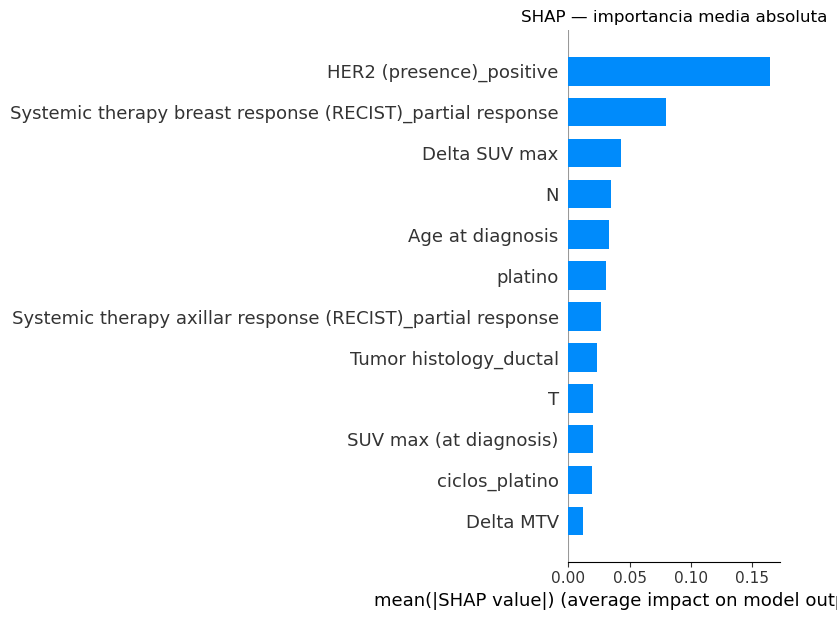

In [46]:
shap.summary_plot(shap_values, datos, plot_type='bar', show=False)
plt.title("SHAP — importancia media absoluta")
plt.tight_layout()
plt.savefig(f"{CARPETA_FIGURAS}/shap_bar.png", dpi=300, bbox_inches='tight')
plt.show()

2. Efecto con signo en variables binarias

Para HER2 positivo, platino, respuesta RECIST, etc.: cuánto cambia de media la probabilidad cuando la variable vale 1 frente a 0.

In [47]:
nombres = list(datos.columns)
sv = pd.DataFrame(shap_values, columns=nombres)

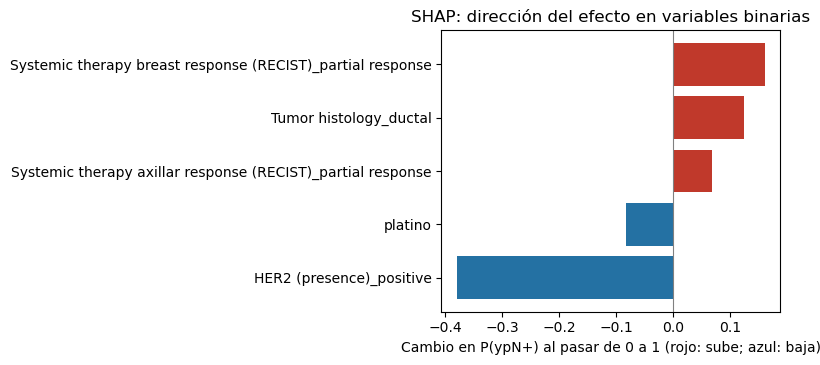

                                                   variable  n_si  shap_si  shap_no  efecto
                                   HER2 (presence)_positive    27   -0.259    0.121  -0.380
                                                    platino    21   -0.062    0.020  -0.082
Systemic therapy axillar response (RECIST)_partial response    23    0.049   -0.018   0.068
                                     Tumor histology_ductal    76    0.013   -0.111   0.124
 Systemic therapy breast response (RECIST)_partial response    42    0.081   -0.079   0.160


In [52]:
es_bin = lambda v: set(datos[v].dropna().unique()) <= {0, 1}
binarias = [v for v in nombres if es_bin(v)]

filas = []
for v in binarias:
    m = datos[v] == 1
    if m.sum() > 0 and (~m).sum() > 0:
        filas.append(dict(variable=v, n_si=int(m.sum()),
                          shap_si=sv.loc[m, v].mean(), shap_no=sv.loc[~m, v].mean()))
bt = pd.DataFrame(filas)
bt['efecto'] = bt['shap_si'] - bt['shap_no']
bt = bt.sort_values('efecto')

colores = np.where(bt['efecto'] > 0, '#c0392b', '#2471a3')
plt.figure(figsize=(8, 0.45*len(bt)+1.5))
plt.barh(bt['variable'], bt['efecto'], color=colores)
plt.axvline(0, color='gray', lw=.8)
plt.xlabel("Cambio en P(ypN+) al pasar de 0 a 1 (rojo: sube; azul: baja)")
plt.title("SHAP: dirección del efecto en variables binarias")
plt.tight_layout()
plt.savefig(f"{CARPETA_FIGURAS}/shap_binarias_signo.png", dpi=300, bbox_inches='tight')
plt.show()
print(bt.round(3).to_string(index=False))
bt.round(3).to_csv(f"{CARPETA_RESULTADOS}/shap_binarias_signo.csv", index=False)

La Figura muestra cuánto cambia, de media, la probabilidad de ypN+ que predice el modelo cuando una variable binaria pasa de 0 a 1, manteniendo el resto de la información de cada paciente. Las barras rojas indican que la probabilidad sube y las azules que baja. El efecto mayor corresponde al HER2 positivo ($-0.380$, 27 pacientes), que reduce claramente la probabilidad de ypN+; le siguen el platino ($-0.082$, 21 pacientes), también con efecto de reducción, y tres variables que la aumentan: la respuesta RECIST parcial de la mama ($+0.160$, 42 pacientes), la histología ductal ($+0.124$, 76 pacientes) y la respuesta RECIST parcial de la axila ($+0.068$, 23 pacientes). En términos clínicos, una respuesta parcial (frente a completa) acompaña a una mayor probabilidad de afectación ganglionar residual, un sentido coherente con lo esperable. Estas cifras describen cómo usa el modelo cada variable y no demuestran causalidad, y tres de ellas requieren cautela: el efecto del HER2 refleja que ninguna de las 27 pacientes HER2 positivas tuvo ypN+; el del platino está confundido con HER2, porque solo se administró a pacientes no HER2 positivas; y el de la histología se apoya en solo 9 pacientes con histología no ductal.

Por ejemplo, el efecto del HER2 positivo es $-0.380$: si se comparan pacientes que solo difieren en el estado HER2, la probabilidad de ypN+ que predice el modelo es, de media, unos 38 puntos porcentuales menor en las HER2 positivas que en las negativas (por ejemplo, un 60\,\% frente a un 22\,\%). En cambio, la respuesta RECIST parcial de la mama ($+0.160$) la aumenta unos 16 puntos porcentuales.

Se muestra el cambio medio en la probabilidad predicha de ypN+ al pasar cada variable binaria de 0 a 1 en el modelo de referencia (diferencia entre el SHAP medio de las pacientes con valor 1 y con valor 0, en unidades de probabilidad). El estado HER2 positivo fue la variable con mayor efecto y redujo la probabilidad predicha en 0,380, coherente con que ninguna de las 27 pacientes HER2 positivas presentó afectación ganglionar residual. La respuesta solo parcial de la mama (+0,160) y de la axila (+0,068) a la terapia sistémica aumentó la probabilidad de ypN+, mientras que haber recibido platino la redujo (−0,082). La histología ductal se asoció a un aumento de 0,124, pero este resultado debe interpretarse con cautela, ya que solo 9 pacientes tenían otra histología. Estos efectos describen cómo utiliza las variables este modelo concreto y no implican causalidad. Además, el efecto del platino no puede separarse del estado HER2, puesto que ninguna de las pacientes tratadas con platino era HER2 positiva.

3. Variables continuas: valor frente a efecto

Para ΔSUVmax, edad, T, N, SUVmax basal y ΔMTV.

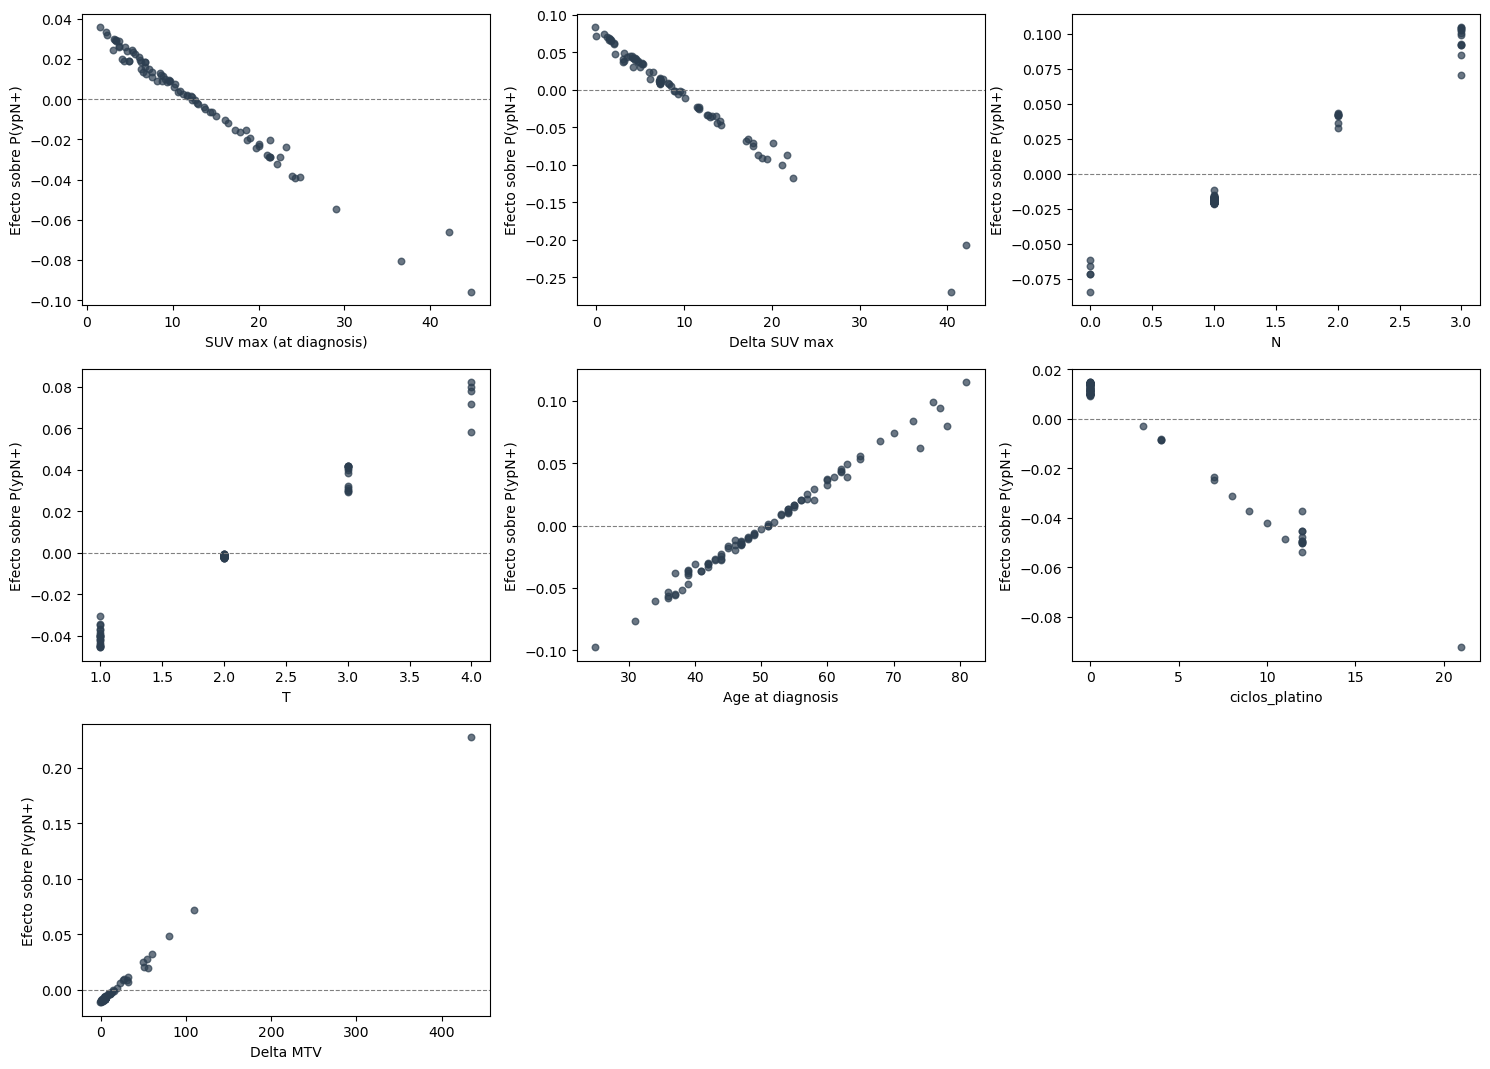

In [53]:
cont = [v for v in nombres if v not in binarias]
n = len(cont); cols = 3; filas_ = int(np.ceil(n/cols))
fig, axs = plt.subplots(filas_, cols, figsize=(5*cols, 3.6*filas_))
for ax, v in zip(np.ravel(axs), cont):
    ax.scatter(datos[v], sv[v], s=22, alpha=.7, color='#2c3e50')
    ax.axhline(0, ls='--', lw=.8, color='gray')
    ax.set_xlabel(v); ax.set_ylabel("Efecto sobre P(ypN+)")
for ax in np.ravel(axs)[n:]:
    ax.axis('off')
plt.tight_layout()
plt.savefig(f"{CARPETA_FIGURAS}/shap_continuas.png", dpi=300, bbox_inches='tight')
plt.show()

4. Probabilidad predicha por grupo (la más intuitiva)

Muestra directamente cómo cambia la probabilidad de ypN+ según HER2 y platino. 

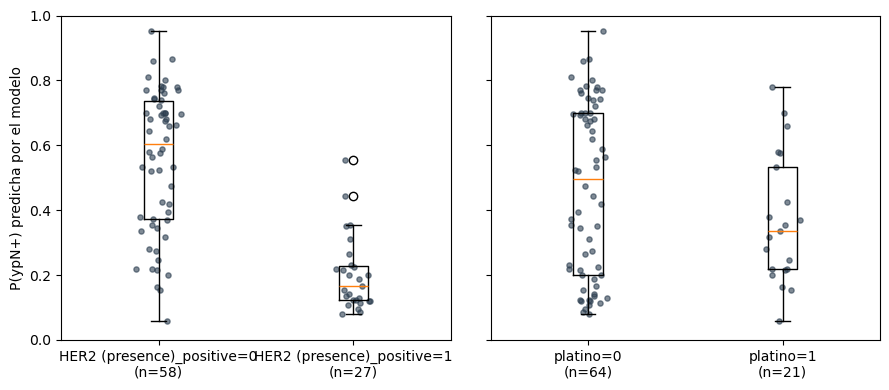

HER2 (presence)_positive       mean  count
0.0  0.517     58
1.0  0.000     27
platino       mean  count
0.0  0.391     64
1.0  0.238     21


In [54]:
p = modelo.predict_proba(datos)[:, 1]
fig, axs = plt.subplots(1, 2, figsize=(9, 4), sharey=True)
for ax, v in zip(axs, ['HER2 (presence)_positive', 'platino']):
    g0, g1 = p[datos[v] == 0], p[datos[v] == 1]
    ax.boxplot([g0, g1], labels=[f"{v}=0\n(n={len(g0)})", f"{v}=1\n(n={len(g1)})"])
    for i, g in enumerate([g0, g1], start=1):
        ax.scatter(np.random.normal(i, 0.05, len(g)), g, s=14, alpha=.6, color='#2c3e50')
    ax.set_ylim(0, 1)
axs[0].set_ylabel("P(ypN+) predicha por el modelo")
plt.tight_layout()
plt.savefig(f"{CARPETA_FIGURAS}/prob_por_grupo.png", dpi=300, bbox_inches='tight')
plt.show()

# Proporción observada de ypN+ en cada grupo (para contrastar con el modelo)
for v in ['HER2 (presence)_positive', 'platino']:
    print(v, y.groupby(datos[v].values).agg(['mean', 'count']).round(3))